# Department of Computer Science and Engineering (Data Science)
**BAD702 – Statistical Machine Learning for Data Science**  
**Project:** Electricity Theft Detection Using Consumption Patterns  
**Name:** Chandana S
  
  **USN:** 1VI23CD011

>

## 1. Problem Definition
Non-technical losses, including electricity theft, are difficult to identify from meter readings alone. This study analyzes historical daily consumption patterns and builds statistical and machine-learning models to prioritize suspicious consumers for investigation. A model flag is **not proof of theft**.

## 2. Objectives
1. Inspect and clean a real electricity consumption dataset.
2. Analyze consumption distributions and variability.
3. Compare labeled normal and theft cases.
4. Test statistical differences and report confidence intervals.
5. Predict a held-out consumption target with regression.
6. Compare supervised theft classifiers with suitable imbalance-aware metrics.

## 3. Research Questions
**RQ1:** How does recorded electricity usage vary across consumers?  
**RQ2:** Do labeled groups differ in consumption distribution or variability?  
**RQ3:** Can historical readings predict a future reading?  
**RQ4:** Can historical consumption features distinguish labeled theft from normal consumers?

## 4. Dataset Description
**Source:** SGCC electricity theft benchmark (daily meter readings, consumer identifiers, binary `FLAG`). The full published dataset has approximately 42,372 consumers and 1,035 daily columns. This notebook automatically tries a publicly mirrored CSV; if it is unavailable, it provides a Colab upload option.

`FLAG=0`: normal-labeled; `FLAG=1`: theft-labeled. Dates are columns; values represent daily recorded electricity usage. Data are from China, not an Indian electricity distributor.

**Source:** https://ieee-pes-data-sharing.org/datasets/detail/663b8e0e-3ace-48f8-b983-4cb59b39fa6f

## 5. Import Libraries

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, IsolationForest
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, average_precision_score,
                             RocCurveDisplay, precision_recall_curve)
from sklearn.inspection import permutation_importance
sns.set_theme(style="whitegrid")
RANDOM_STATE=42


## 6. Load the Dataset
This cell attempts a public GitHub mirror of the SGCC CSV. If the download fails, use the upload dialog. **No synthetic data is substituted for real observations.**

In [ ]:
import os, requests
from google.colab import files
url = 'https://raw.githubusercontent.com/safashafqaat/electricity-theft-detection-ml/main/SGCC_Electricity_Theft.csv'
path = '/content/sgcc_electricity.csv'
if not os.path.exists(path):
    try:
        with requests.get(url, stream=True, timeout=40) as r:
            r.raise_for_status()
            with open(path, 'wb') as f:
                for chunk in r.iter_content(chunk_size=1024*1024):
                    if chunk: f.write(chunk)
        print('Dataset downloaded:', round(os.path.getsize(path)/1e6,1), 'MB')
    except Exception as e:
        print('Automatic download failed:', str(e)[:180]); print('Upload an SGCC CSV from the dataset source.')
        uploaded=files.upload()
        path=next(iter(uploaded))
raw=pd.read_csv(path, low_memory=False)
print('Raw shape:',raw.shape)
display(raw.iloc[:5,:8])

Dataset downloaded: 3.8 MB
Raw shape: (25863, 28)


,01/01/2014,01/02/2014,01/03/2014,01/04/2014,01/05/2014,01/06/2014,01/07/2014,01/08/2014
0,2401.0,2500.0,2674.0,2432.00,2231.00,1942.00,2752.00,1244.00
1,3318.0,282.0,540.0,5670.00,4854.00,4170.00,4848.00,3546.00
2,1020.8,1097.4,1377.4,1408.80,1414.80,1387.40,1444.60,1325.00
3,0.0,1183.8,1190.4,1183.80,0.00,1154.40,1166.40,1183.80
4,1445.7,1348.2,1281.9,1276.35,1219.95,1289.85,1298.55,1326.15


## 7. Initial Dataset Inspection

In [ ]:
print('Shape:',raw.shape)
print('First 12 columns:',raw.columns[:12].tolist())
print('Last 5 columns:',raw.columns[-5:].tolist())
print('Duplicate rows:',raw.duplicated().sum())
print('Missing entries:',int(raw.isna().sum().sum()))
display(raw.dtypes.value_counts().rename('column count'))

Shape: (25863, 28)
First 12 columns: ['01/01/2014', '01/02/2014', '01/03/2014', '01/04/2014', '01/05/2014', '01/06/2014', '01/07/2014', '01/08/2014', '01/09/2014', '01/10/2014', '01/11/2014', '01/12/2014']
Last 5 columns: ['1/24/2014', '1/25/2014', '1/26/2014', 'CONS_NO', 'FLAG']
Duplicate rows: 0
Missing entries: 125


,column count
float64,26
object,1
int64,1


## 8. Data Preprocessing
Parse date columns, coerce readings to numeric, retain missingness information, and avoid using the label or customer ID as predictors. Missing consumption readings are **not automatically interpreted as zero usage**.

In [ ]:
raw.columns=[str(c).strip() for c in raw.columns]
label_col=next((c for c in raw.columns if c.upper()=='FLAG'),None)
if label_col is None: raise ValueError('FLAG label not found. Check that this is the SGCC labeled dataset.')
parsed=pd.to_datetime(pd.Index(raw.columns),errors='coerce',dayfirst=False)
date_cols=[c for c,d in zip(raw.columns,parsed) if pd.notna(d) and c!=label_col]
date_cols=sorted(date_cols,key=lambda c:pd.to_datetime(c))
if len(date_cols)<20: raise ValueError('Fewer than 20 date columns detected. Check CSV format.')
y=pd.to_numeric(raw[label_col],errors='coerce')
valid=y.isin([0,1]); y=y.loc[valid].astype(int).reset_index(drop=True)
readings=raw.loc[valid,date_cols].apply(pd.to_numeric,errors='coerce').reset_index(drop=True)
readings=readings.mask(readings<0)
print('Valid customers:',len(y),'daily columns:',len(date_cols))
print('Date range:',date_cols[0],'to',date_cols[-1]); print('Label counts:');print(y.value_counts())

Valid customers: 25863 daily columns: 26
Date range: 01/01/2014 to 1/26/2014
Label counts:
FLAG
0    23741
1     2122
Name: count, dtype: int64


## 9. Data Quality Verification

In [ ]:
quality=pd.DataFrame({'metric':['customers','days','missing fraction','all-missing consumers','negative values after cleaning','theft-label fraction'],
'value':[len(y),len(date_cols),readings.isna().mean().mean(),readings.isna().all(axis=1).sum(),(readings<0).sum().sum(),y.mean()]})
display(quality)
assert y.isin([0,1]).all()
assert (readings.dropna().to_numpy()>=0).all()

,metric,value
0,customers,25863.000000
1,days,26.000000
2,missing fraction,0.000186
3,all-missing consumers,0.000000
4,negative values after cleaning,0.000000
5,theft-label fraction,0.082048


## 10. Descriptive Statistics

In [ ]:
features=pd.DataFrame(index=readings.index)
features['mean_kwh']=readings.mean(axis=1)
features['median_kwh']=readings.median(axis=1)
features['std_kwh']=readings.std(axis=1)
features['min_kwh']=readings.min(axis=1)
features['max_kwh']=readings.max(axis=1)
features['q25_kwh']=readings.quantile(.25,axis=1)
features['q75_kwh']=readings.quantile(.75,axis=1)
features['iqr_kwh']=features.q75_kwh-features.q25_kwh
features['zero_fraction']=(readings==0).sum(axis=1)/readings.notna().sum(axis=1).replace(0,np.nan)
features['missing_fraction']=readings.isna().mean(axis=1)
features['cv']=features.std_kwh/(features.mean_kwh+1e-6)
features['theft_label']=y
print('Consumer-level descriptive statistics:');display(features.describe().T.round(3))

Consumer-level descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
mean_kwh,25863.0,7.967,129.093,0.0,0.633,3.912,8.456,19807.698
median_kwh,25863.0,6.899,33.426,0.0,0.000,3.575,8.465,3366.000
std_kwh,25863.0,7.502,638.296,0.0,0.421,1.606,3.143,100998.132
min_kwh,25863.0,2.422,12.949,0.0,0.000,0.000,2.320,1012.200
max_kwh,25863.0,36.748,3254.489,0.0,2.110,8.170,15.150,514991.780
q25_kwh,25863.0,5.374,24.912,0.0,0.000,2.210,6.672,2167.500
q75_kwh,25863.0,8.559,39.243,0.0,0.425,4.945,10.350,3964.500
iqr_kwh,25863.0,3.186,18.148,0.0,0.098,1.500,3.300,1797.000
zero_fraction,25863.0,0.286,0.384,0.0,0.000,0.077,0.538,1.000
missing_fraction,25863.0,0.000,0.006,0.0,0.000,0.000,0.000,0.462


## 11. Electricity Consumption Distribution

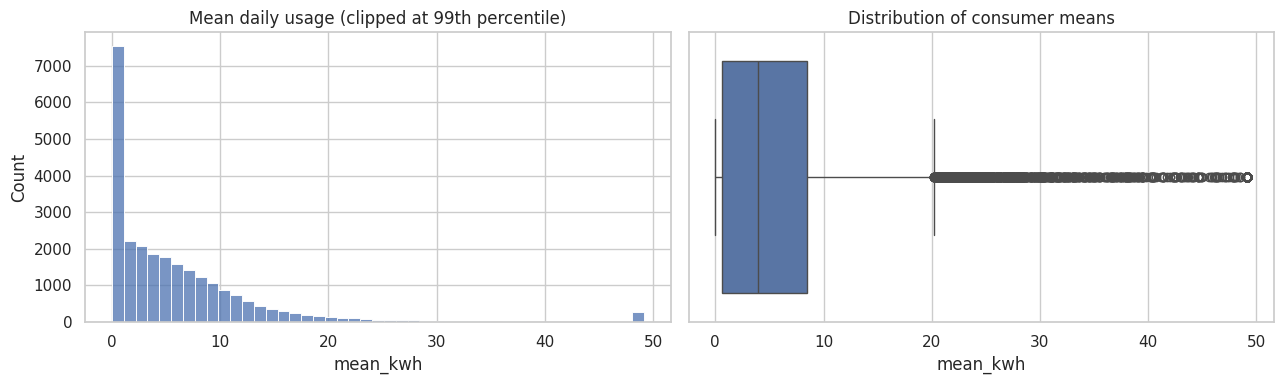

In [ ]:
fig,ax=plt.subplots(1,2,figsize=(13,4))
sns.histplot(features.mean_kwh.clip(upper=features.mean_kwh.quantile(.99)),bins=45,ax=ax[0]);ax[0].set_title('Mean daily usage (clipped at 99th percentile)')
sns.boxplot(x=features.mean_kwh.clip(upper=features.mean_kwh.quantile(.99)),ax=ax[1]);ax[1].set_title('Distribution of consumer means')
plt.tight_layout();plt.show()

## 12. Normal vs Theft-Labeled Consumer Distribution

             mean_kwh   std_kwh  zero_fraction
theft_label                                   
0            3.788462  1.568526       0.076923
1            5.294423  2.073006       0.000000


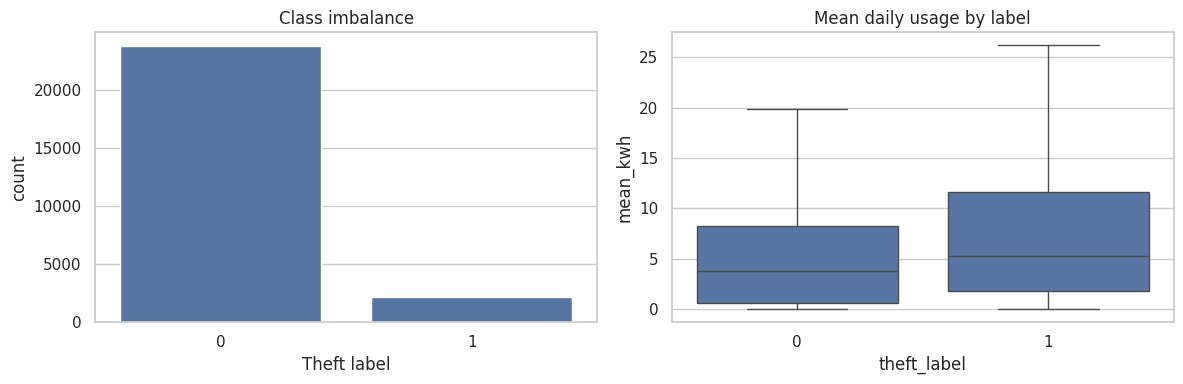

In [ ]:
print(features.groupby('theft_label')[['mean_kwh','std_kwh','zero_fraction']].median())
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.countplot(x=y,ax=ax[0]);ax[0].set_title('Class imbalance');ax[0].set_xlabel('Theft label')
sns.boxplot(data=features,x='theft_label',y='mean_kwh',showfliers=False,ax=ax[1]);ax[1].set_title('Mean daily usage by label')
plt.tight_layout();plt.show()

## 13. Consumer-Wise Consumption Analysis

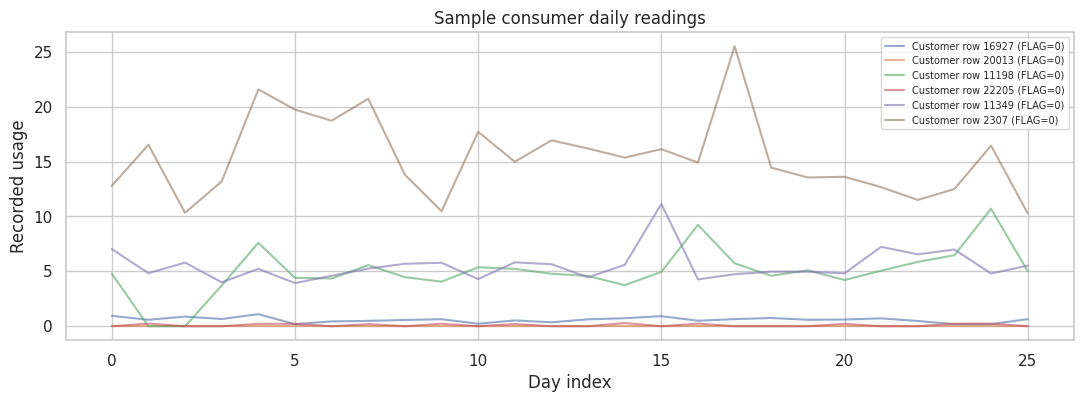

In [ ]:
sample_ids=np.random.default_rng(RANDOM_STATE).choice(len(readings),size=min(6,len(readings)),replace=False)
plt.figure(figsize=(13,4))
for i in sample_ids:
    plt.plot(np.arange(len(date_cols)),readings.iloc[i].to_numpy(),alpha=.6,label=f'Customer row {i} (FLAG={y.iloc[i]})')
plt.title('Sample consumer daily readings');plt.xlabel('Day index');plt.ylabel('Recorded usage');plt.legend(fontsize=7);plt.show()

## 14. Temporal Consumption Pattern Analysis

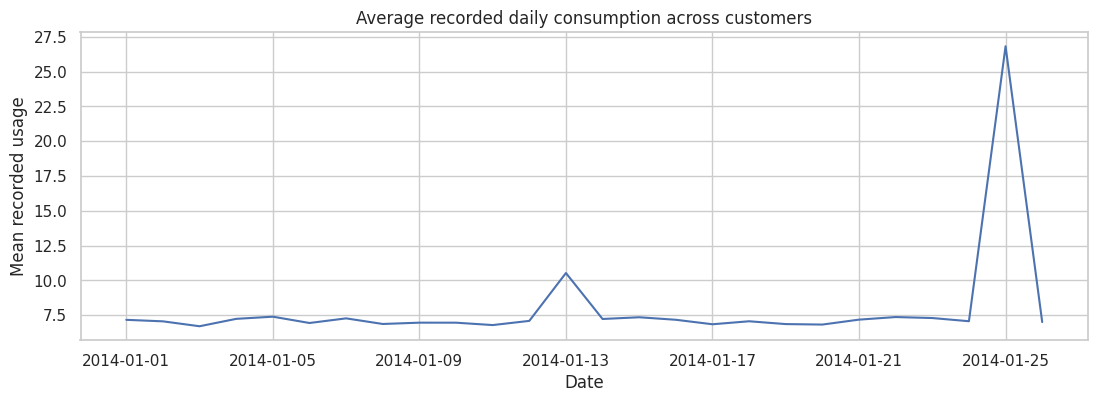

First 5 daily means:


,0
01/01/2014,7.168849
01/02/2014,7.059998
01/03/2014,6.707204
01/04/2014,7.238823
01/05/2014,7.394637


In [ ]:
daily_mean=readings.mean(axis=0)
plt.figure(figsize=(13,4));plt.plot(pd.to_datetime(date_cols),daily_mean.values);plt.title('Average recorded daily consumption across customers');plt.xlabel('Date');plt.ylabel('Mean recorded usage');plt.show()
print('First 5 daily means:');display(daily_mean.head())

## 15. Consumption Variability and Anomaly Analysis

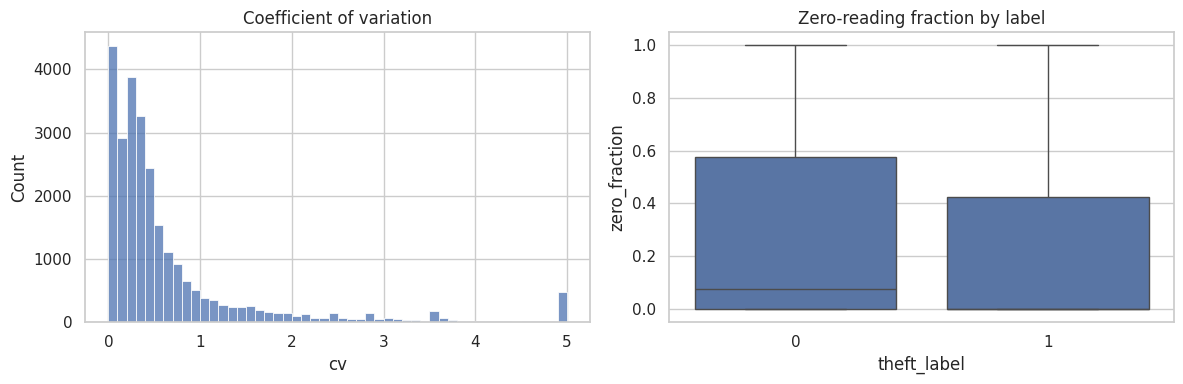

In [ ]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.histplot(features.cv.replace([np.inf,-np.inf],np.nan).clip(upper=5),bins=50,ax=ax[0]);ax[0].set_title('Coefficient of variation')
sns.boxplot(data=features,x='theft_label',y='zero_fraction',showfliers=False,ax=ax[1]);ax[1].set_title('Zero-reading fraction by label')
plt.tight_layout();plt.show()

## 16. Correlation Analysis

In [ ]:
corr=features.drop(columns='theft_label').corr()
plt.figure(figsize=(10,7));sns.heatmap(corr,cmap='coolwarm',center=0);plt.title('Consumer feature correlations');plt.tight_layout();plt.show()

## 17. Statistical Hypothesis Testing
All tests use α = 0.05. These tests describe associations, not causal evidence of theft.

### 17.1 Confidence Interval for Mean Consumption

In [ ]:
v=features.mean_kwh.dropna().to_numpy();m=v.mean();sem=stats.sem(v)
ci=stats.t.interval(.95,len(v)-1,loc=m,scale=sem)
print(f'Mean daily consumer consumption: {m:.3f}; 95% CI: ({ci[0]:.3f}, {ci[1]:.3f})')

Mean daily consumer consumption: 7.967; 95% CI: (6.394, 9.540)


### 17.2 Hypothesis Test – Consumption by Theft Label
H₀: Distributions of consumer mean usage are identical across labels. H₁: They differ. Use two-sided Mann–Whitney U; repeated days are aggregated at consumer level.

In [ ]:
a=features.loc[y==0,'mean_kwh'].dropna();b=features.loc[y==1,'mean_kwh'].dropna()
res=stats.mannwhitneyu(a,b,alternative='two-sided')
print('U statistic:',res.statistic,'p-value:',res.pvalue,'Reject H0:',res.pvalue<.05)
print('Median normal:',a.median(),'Median theft-labeled:',b.median())

U statistic: 21015969.5 p-value: 7.281291230142501e-37 Reject H0: True
Median normal: 3.7884615384615383 Median theft-labeled: 5.294423076923078


### 17.3 Hypothesis Test – Consumption Variability by Label

In [ ]:
a=features.loc[y==0,'cv'].replace([np.inf,-np.inf],np.nan).dropna()
b=features.loc[y==1,'cv'].replace([np.inf,-np.inf],np.nan).dropna()
res2=stats.mannwhitneyu(a,b,alternative='two-sided')
print('U:',res2.statistic,'p-value:',res2.pvalue,'Reject H0:',res2.pvalue<.05)

U: 25638243.0 p-value: 0.17232485796678831 Reject H0: False


## 18. Feature Selection and Model Preparation
**Leakage control:** For regression, predict the last 20% of days using features from the first 80%. For classification, extract features only from the first 80% of days; the remaining days are not used. Split **by customer**, not by daily record.

In [ ]:
cut=int(len(date_cols)*.8)
hist=readings.iloc[:,:cut]; future=readings.iloc[:,cut:]
def make_features(r):
    f=pd.DataFrame(index=r.index)
    f['mean']=r.mean(axis=1);f['median']=r.median(axis=1);f['std']=r.std(axis=1)
    f['min']=r.min(axis=1);f['max']=r.max(axis=1)
    f['iqr']=r.quantile(.75,axis=1)-r.quantile(.25,axis=1)
    f['zero_fraction']=(r==0).sum(axis=1)/r.notna().sum(axis=1).replace(0,np.nan)
    f['missing_fraction']=r.isna().mean(axis=1)
    f['cv']=f['std']/(f['mean']+1e-6)
    mid=r.shape[1]//2
    f['recent_vs_early']=r.iloc[:,mid:].mean(axis=1)/(r.iloc[:,:mid].mean(axis=1)+1e-6)
    return f.replace([np.inf,-np.inf],np.nan)
X=make_features(hist)
idx=np.arange(len(y)); train_idx,test_idx=train_test_split(idx,test_size=.2,stratify=y,random_state=RANDOM_STATE)
X_train,X_test=X.iloc[train_idx],X.iloc[test_idx]
y_train,y_test=y.iloc[train_idx],y.iloc[test_idx]
print('Training consumers:',len(train_idx),'Test consumers:',len(test_idx));display(X.head())

Training consumers: 20690 Test consumers: 5173


,mean,median,std,min,max,iqr,zero_fraction,missing_fraction,cv,recent_vs_early
0,2074.30,2295.5,670.905445,343.00,3167.0,525.250,0.00,0.0,0.323437,0.835258
1,3405.60,3600.0,1432.999298,282.00,5670.0,975.000,0.00,0.0,0.420777,0.912721
2,1324.43,1364.4,144.908846,1012.20,1540.6,138.550,0.00,0.0,0.109412,1.008081
3,986.58,1162.5,426.743329,0.00,1228.2,81.300,0.15,0.0,0.432548,1.097723
4,1282.74,1309.8,128.078657,1006.65,1445.7,132.225,0.00,0.0,0.099848,0.932718


## 19. Multiple Linear Regression – Future Consumption Prediction
Target: mean recorded consumption over the last 20% of days. Predictors: features extracted from earlier days. The target is not used to construct the features.

In [ ]:
future_target=future.mean(axis=1)
valid_train=future_target.iloc[train_idx].notna();valid_test=future_target.iloc[test_idx].notna()
Xr_train=X_train.loc[valid_train];Xr_test=X_test.loc[valid_test]
yr_train=future_target.iloc[train_idx].loc[valid_train];yr_test=future_target.iloc[test_idx].loc[valid_test]
reg=make_pipeline(SimpleImputer(strategy='median',add_indicator=True),StandardScaler(),LinearRegression())
reg.fit(Xr_train,yr_train);pred_lr=reg.predict(Xr_test)
def regression_scores(name,truth,pred):
    return {'Model':name,'MAE':mean_absolute_error(truth,pred),'RMSE':np.sqrt(mean_squared_error(truth,pred)),'R2':r2_score(truth,pred)}
reg_results=[regression_scores('Linear Regression',yr_test,pred_lr)]
display(pd.DataFrame(reg_results))

,Model,MAE,RMSE,R2
0,Linear Regression,11.176103,21.836927,-1.176117


### 19.2 Baseline Regression Model

In [ ]:
baseline=DummyRegressor(strategy='mean');baseline.fit(Xr_train,yr_train)
pred_base=baseline.predict(Xr_test)
reg_results.insert(0,regression_scores('Mean Baseline',yr_test,pred_base))
display(pd.DataFrame(reg_results).round(3))

,Model,MAE,RMSE,R2
0,Mean Baseline,8.556,15.486,-0.094
1,Linear Regression,11.176,21.837,-1.176


### 19.3 Regression Diagnostics

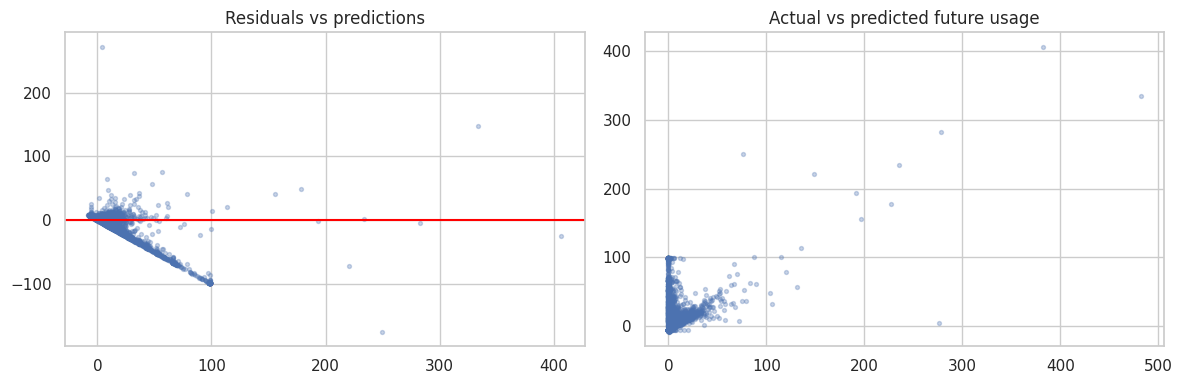

In [ ]:
fig,ax=plt.subplots(1,2,figsize=(12,4));ax[0].scatter(pred_lr,yr_test-pred_lr,s=8,alpha=.3);ax[0].axhline(0,color='red');ax[0].set_title('Residuals vs predictions')
ax[1].scatter(yr_test,pred_lr,s=8,alpha=.3);ax[1].set_title('Actual vs predicted future usage');plt.tight_layout();plt.show()

## 20. Random Forest Regression – Comparison Model

In [ ]:
rf_reg=make_pipeline(SimpleImputer(strategy='median',add_indicator=True),RandomForestRegressor(n_estimators=90,min_samples_leaf=5,n_jobs=-1,random_state=RANDOM_STATE))
rf_reg.fit(Xr_train,yr_train);pred_rf=rf_reg.predict(Xr_test)
reg_results.append(regression_scores('Random Forest Regression',yr_test,pred_rf))
display(pd.DataFrame(reg_results).round(3))

,Model,MAE,RMSE,R2
0,Mean Baseline,8.556,15.486,-0.094
1,Linear Regression,11.176,21.837,-1.176
2,Random Forest Regression,6.234,218.530,-216.932


### 20.1 Random Forest Regression – Feature Importance

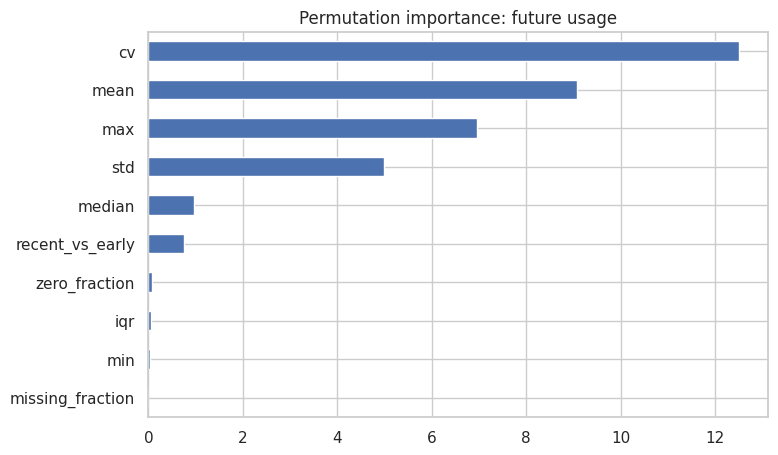

In [ ]:
imp=permutation_importance(rf_reg,Xr_test,yr_test,n_repeats=3,random_state=RANDOM_STATE,n_jobs=1,scoring='neg_mean_absolute_error')
pd.Series(imp.importances_mean,index=X.columns).sort_values().plot.barh(figsize=(8,5),title='Permutation importance: future usage');plt.show()

## 21. Electricity Theft Classification
The class is imbalanced. Evaluate against a majority-class baseline. All preprocessing is fitted on training data only.

In [ ]:
clf_base=DummyClassifier(strategy='most_frequent');clf_base.fit(X_train,y_train)
logit=make_pipeline(SimpleImputer(strategy='median',add_indicator=True),StandardScaler(),LogisticRegression(max_iter=1000,class_weight='balanced',random_state=RANDOM_STATE))
forest=make_pipeline(SimpleImputer(strategy='median',add_indicator=True),RandomForestClassifier(n_estimators=140,min_samples_leaf=3,class_weight='balanced_subsample',n_jobs=-1,random_state=RANDOM_STATE))
models={'Majority baseline':clf_base,'Logistic Regression':logit,'Random Forest':forest}
for name,model in models.items():
    if name!='Majority baseline':model.fit(X_train,y_train)
print('Class counts in training:',y_train.value_counts().to_dict())

Class counts in training: {0: 18992, 1: 1698}


### 21.1 Logistic Regression

In [ ]:
p_logit=logit.predict_proba(X_test)[:,1]
print('Logistic Regression ROC-AUC:',roc_auc_score(y_test,p_logit),'PR-AUC:',average_precision_score(y_test,p_logit))

Logistic Regression ROC-AUC: 0.6160601834745746 PR-AUC: 0.1653294153780419


### 21.2 Random Forest Classifier

In [ ]:
p_forest=forest.predict_proba(X_test)[:,1]
print('Random Forest ROC-AUC:',roc_auc_score(y_test,p_forest),'PR-AUC:',average_precision_score(y_test,p_forest))

Random Forest ROC-AUC: 0.5992902676631029 PR-AUC: 0.1481289580704217


## 22. Classification Reports

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
class_results=[]
for name,model in models.items():
    pred=model.predict(X_test); prob=model.predict_proba(X_test)[:,1]
    print('\n',name,'\n',classification_report(y_test,pred,zero_division=0))
    class_results.append({'Model':name,'Accuracy':accuracy_score(y_test,pred),'Precision':precision_score(y_test,pred,zero_division=0),'Recall':recall_score(y_test,pred,zero_division=0),'F1':f1_score(y_test,pred,zero_division=0),'ROC-AUC':roc_auc_score(y_test,prob),'PR-AUC':average_precision_score(y_test,prob)})


 Majority baseline 
               precision    recall  f1-score   support

           0       0.92      1.00      0.96      4749
           1       0.00      0.00      0.00       424

    accuracy                           0.92      5173
   macro avg       0.46      0.50      0.48      5173
weighted avg       0.84      0.92      0.88      5173


 Logistic Regression 
               precision    recall  f1-score   support

           0       0.93      0.75      0.83      4749
           1       0.13      0.41      0.19       424

    accuracy                           0.73      5173
   macro avg       0.53      0.58      0.51      5173
weighted avg       0.87      0.73      0.78      5173


 Random Forest 
               precision    recall  f1-score   support

           0       0.92      0.99      0.95      4749
           1       0.37      0.08      0.13       424

    accuracy                           0.91      5173
   macro avg       0.65      0.53      0.54      5173
weighted a

## 23. Confusion Matrices

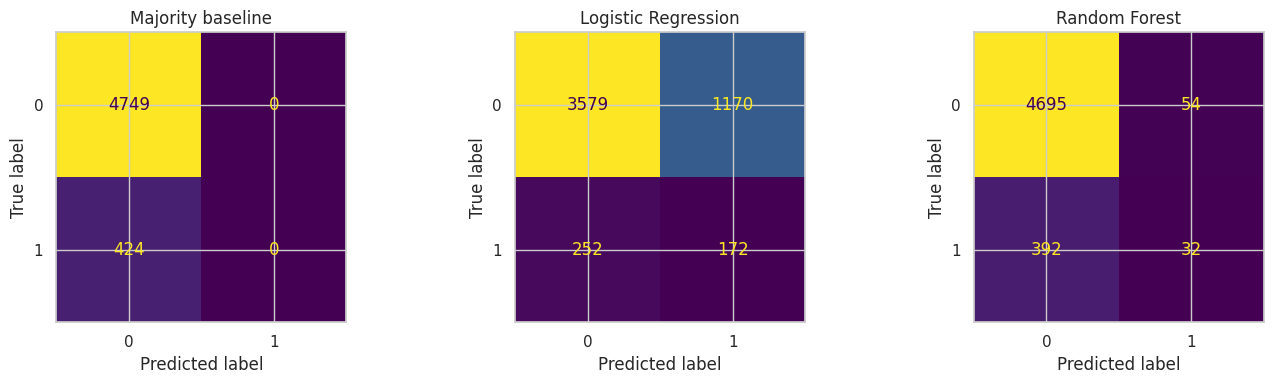

In [ ]:
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,(name,model) in zip(axes,models.items()):
    ConfusionMatrixDisplay.from_predictions(y_test,model.predict(X_test),ax=ax,colorbar=False);ax.set_title(name)
plt.tight_layout();plt.show()

## 24. Model Comparison

REGRESSION


,Model,MAE,RMSE,R2
0,Mean Baseline,8.556,15.486,-0.094
1,Linear Regression,11.176,21.837,-1.176
2,Random Forest Regression,6.234,218.530,-216.932


CLASSIFICATION


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Majority baseline,0.918,0.000,0.000,0.000,0.500,0.082
1,Logistic Regression,0.725,0.128,0.406,0.195,0.616,0.165
2,Random Forest,0.914,0.372,0.075,0.125,0.599,0.148


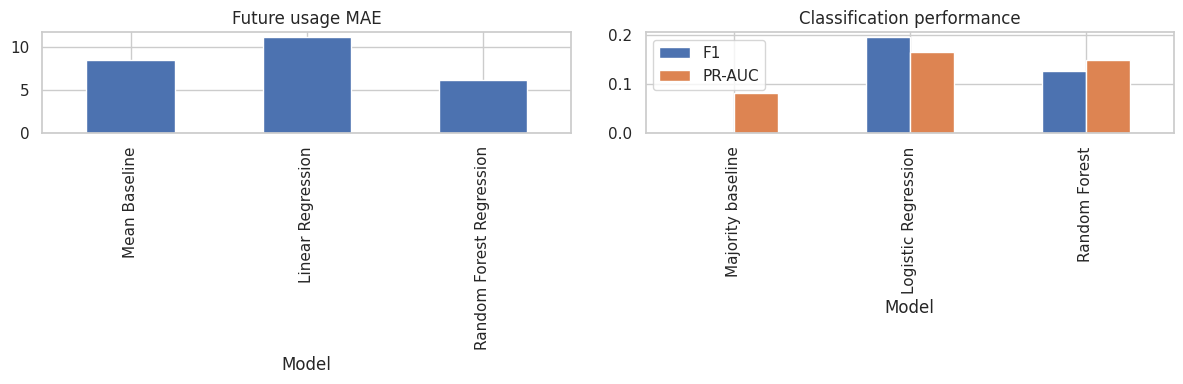

In [ ]:
print('REGRESSION');display(pd.DataFrame(reg_results).round(3))
print('CLASSIFICATION');display(pd.DataFrame(class_results).round(3))
fig,axes=plt.subplots(1,2,figsize=(12,4))
pd.DataFrame(reg_results).plot.bar(x='Model',y='MAE',ax=axes[0],legend=False,title='Future usage MAE')
pd.DataFrame(class_results).plot.bar(x='Model',y=['F1','PR-AUC'],ax=axes[1],title='Classification performance')
plt.tight_layout();plt.show()

## 25. Key Findings
**Complete this section after executing all cells.** Use the tables printed above, not assumed results.

- Report the observed label proportions.
- State the measured median consumption and variability by label.
- Report the confidence interval and both hypothesis-test p-values.
- Identify the lowest regression MAE and best classification PR-AUC/F1.
- Discuss the recall/precision trade-off and false-positive investigations.

## 26. Limitations
1. SGCC readings are from China and may not generalize to Indian distribution networks.
2. Theft labels may reflect inspection practices and imperfect coverage.
3. Missing values, meter faults, seasonal changes and legitimate demand reductions can resemble anomalies.
4. The dataset lacks weather, tariff, household and equipment context.
5. Random customer splits estimate performance on new customers from the same historical period, not future deployment drift.
6. Model scores support **review**, not accusations or automatic penalties.

## 27. Conclusion
This notebook provides a reproducible statistical machine learning workflow for electricity consumption and theft-label analysis. After execution, interpret the actual statistical tests and held-out model metrics. A useful model must balance detection recall against the cost of investigating legitimate consumers.

**References:** SGCC benchmark dataset (IEEE PES Data Sharing); Zheng et al. (2018), *Wide and Deep Convolutional Neural Networks for Electricity-Theft Detection to Secure Smart Grids*.